# Alzheimer's MRI classification: training notebook

Trains a four-class classifier (MildDemented, ModerateDemented, NonDemented, VeryMildDemented) on the
public *Alzheimer MRI* dataset ([Falah/Alzheimer_MRI](https://huggingface.co/datasets/Falah/Alzheimer_MRI) on Hugging Face, no login needed) and exports the model used by the Flask app.

**Run in Google Colab with a GPU:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all.

Outputs, all written to `export/` and downloaded as one zip:
- `model.tflite`, `labels.json`, `metrics.json`, `confusion_matrix.png`, `training_curves.png` → put these five in the repo's `artifacts/` folder (the app loads the model from there)
- `model.keras` → full Keras model, for further work (not committed)

**Commit this notebook with its outputs visible.** The printed scores are the evidence behind any number you quote.

## 1. Setup

In [ ]:
import json, os, random
from pathlib import Path

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_HEIGHT, IMG_WIDTH = 128, 128   # the dataset's native size; the app uses the same
BATCH_SIZE = 32
EXPORT = Path("export"); EXPORT.mkdir(exist_ok=True)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download the dataset
Downloads the public [Falah/Alzheimer_MRI](https://huggingface.co/datasets/Falah/Alzheimer_MRI) dataset from Hugging Face: 6,400 axial MRI slices at 128×128 in four classes, with a fixed train/test split. No account or API key is needed.

In [ ]:
try:
    from datasets import load_dataset
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"], check=True)
    from datasets import load_dataset

raw = load_dataset("Falah/Alzheimer_MRI")
print(raw)

label_feature = raw["train"].features["label"]
if hasattr(label_feature, "names"):
    class_names = [n.replace("_", "") for n in label_feature.names]
else:  # label order documented on the dataset card
    class_names = ["MildDemented", "ModerateDemented", "NonDemented", "VeryMildDemented"]
print("Classes:", class_names)
for split in raw:
    print(split, dict(zip(class_names, np.bincount(raw[split]["label"], minlength=len(class_names)))))

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 5120
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1280
    })
})
Classes: ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']
train {'MildDemented': np.int64(724), 'ModerateDemented': np.int64(49), 'NonDemented': np.int64(2566), 'VeryMildDemented': np.int64(1781)}
test {'MildDemented': np.int64(172), 'ModerateDemented': np.int64(15), 'NonDemented': np.int64(634), 'VeryMildDemented': np.int64(459)}


## 3. Load the data

The dataset ships with a fixed train/test split. The **test set is held out completely** and only used once, at the end.
A stratified 20% of the training split is used for validation.

**Known limitation:** this dataset has no patient IDs, and neighbouring slices from the same person can appear in both
splits. That leakage can inflate scores, so treat the final accuracy as an upper bound, not as real-world performance.

In [ ]:
from sklearn.model_selection import train_test_split

def to_arrays(split):
    X = np.stack([np.asarray(img.convert("RGB").resize((IMG_WIDTH, IMG_HEIGHT)), dtype=np.uint8) for img in split["image"]])
    y = np.asarray(split["label"], dtype=np.int64)
    return X, y

X_trval, y_trval = to_arrays(raw["train"])
X_test, y_test = to_arrays(raw["test"])
X_train, X_val, y_train_arr, y_val = train_test_split(
    X_trval, y_trval, test_size=0.2, stratify=y_trval, random_state=SEED)
print("train", X_train.shape, "| val", X_val.shape, "| test", X_test.shape)

AUTOTUNE = tf.data.AUTOTUNE
def make_ds(X, y, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED)
    # images stay uint8 in memory and become float32 per batch
    return ds.batch(BATCH_SIZE).map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

train_ds = make_ds(X_train, y_train_arr, shuffle=True)
val_ds = make_ds(X_val, y_val, shuffle=False)
test_ds = make_ds(X_test, y_test, shuffle=False)

train (4096, 128, 128, 3) | val (1024, 128, 128, 3) | test (1280, 128, 128, 3)


The classes are heavily imbalanced (ModerateDemented is tiny), so the loss is weighted per class. That stops the model from simply ignoring rare classes.

In [ ]:
y_train = np.concatenate([y.numpy() for _, y in train_ds])
raw_weights = compute_class_weight("balanced", classes=np.arange(len(class_names)), y=y_train)
# Square-root softening: still favours rare classes, but a 26x weight on 39 images makes training unstable
weights = np.sqrt(raw_weights)
class_weight = dict(enumerate(weights))
for name, n, w in zip(class_names, np.bincount(y_train), weights):
    print(f"{name:18s} {n:5d} images  weight {w:.2f}")

MildDemented         579 images  weight 1.33
ModerateDemented      39 images  weight 5.12
NonDemented         2053 images  weight 0.71
VeryMildDemented    1425 images  weight 0.85


## 4. Model

Transfer learning from **MobileNetV2** pretrained on ImageNet, with a small classification head.
MobileNetV2 is light enough to run on a free-tier server's CPU. Pixel scaling and augmentation are
built into the model, so the app only has to resize the image.

In [ ]:
augment = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
], name="augmentation")

base = tf.keras.applications.MobileNetV2(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = tf.keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))      # raw pixels, 0-255
x = augment(inputs)
x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1)(x)          # MobileNetV2 expects [-1, 1]
x = base(x)   # BatchNorm adapts to MRI statistics once the backbone is unfrozen
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(len(class_names), activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)
model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Train
Stage 1 trains only the new head for a few epochs. Stage 2 unfreezes the entire MobileNetV2 backbone and fine-tunes it at a learning rate of 1e-4, because MRI slices differ a lot from ImageNet photos. Early stopping keeps the best epoch by validation loss.

In [ ]:
def callbacks(patience):
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3)]

# Stage 1: train only the new head
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=5, class_weight=class_weight, callbacks=callbacks(3))

# Stage 2: unfreeze the whole backbone. MRI slices look nothing like ImageNet photos,
# so the network needs to adapt all its layers, including BatchNorm statistics.
base.trainable = True
model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=40, class_weight=class_weight, callbacks=callbacks(8))

Epoch 1/5
128/128 ━━━━━━━━━━━━━━━━━━━━ 11s 42ms/step - accuracy: 0.4417 - loss: 1.2431 - val_accuracy: 0.5547 - val_loss: 0.9637 - learning_rate: 0.0010
Epoch 2/5
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.5105 - loss: 1.0443 - val_accuracy: 0.5586 - val_loss: 0.9321 - learning_rate: 0.0010
Epoch 3/5
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.5295 - loss: 1.0118 - val_accuracy: 0.5781 - val_loss: 0.9039 - learning_rate: 0.0010
Epoch 4/5
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.5444 - loss: 0.9523 - val_accuracy: 0.5479 - val_loss: 0.9529 - learning_rate: 0.0010
Epoch 5/5
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.5557 - loss: 0.9581 - val_accuracy: 0.5332 - val_loss: 1.0009 - learning_rate: 0.0010
Epoch 1/40
128/128 ━━━━━━━━━━━━━━━━━━━━ 40s 123ms/step - accuracy: 0.5254 - loss: 1.1853 - val_accuracy: 0.4736 - val_loss: 1.2260 - learning_rate: 1.0000e-04
Epoch 2/40
128/128 ━━━━━━━━━━━━━━━━━━━━ 14s 113ms/step - accuracy: 0.6047 - loss

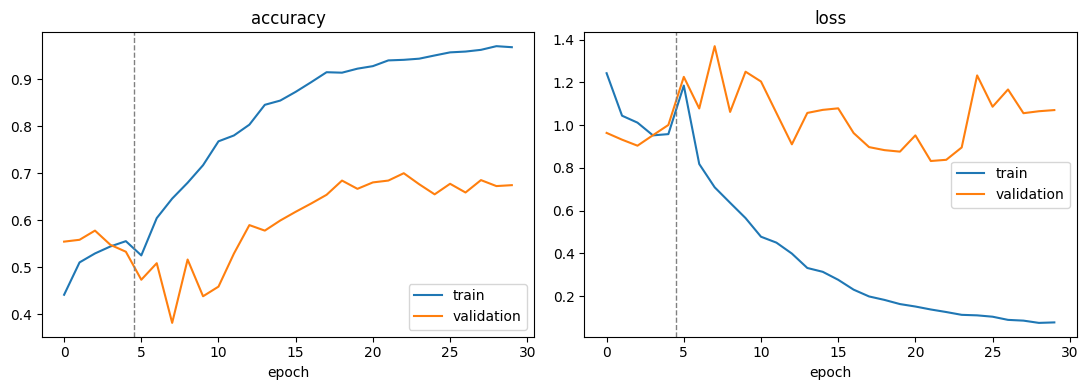

In [ ]:
def joined(key):
    return hist1.history[key] + hist2.history[key]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, key in zip(axes, ["accuracy", "loss"]):
    ax.plot(joined(key), label="train"); ax.plot(joined("val_" + key), label="validation")
    ax.axvline(len(hist1.history["loss"]) - 0.5, color="grey", linestyle="--", linewidth=1)
    ax.set_title(key); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.savefig(EXPORT / "training_curves.png", dpi=120); plt.show()

## 6. Evaluate on the held-out test set
This is the only time the test set is used. These are the numbers to report.

40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step
                  precision    recall  f1-score   support

    MildDemented      0.747     0.430     0.546       172
ModerateDemented      0.667     0.933     0.778        15
     NonDemented      0.725     0.798     0.760       634
VeryMildDemented      0.634     0.638     0.636       459

        accuracy                          0.693      1280
       macro avg      0.693     0.700     0.680      1280
    weighted avg      0.695     0.693     0.687      1280

Test accuracy 0.6930 | macro F1 0.6800 | weighted F1 0.6870


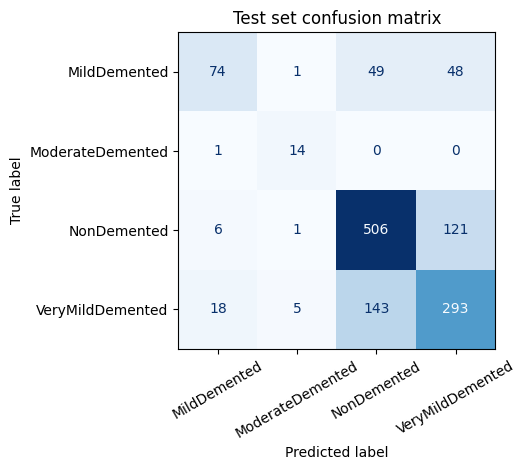

In [ ]:
probs = model.predict(test_ds)
y_pred = probs.argmax(axis=1)
y_true = np.concatenate([y.numpy() for _, y in test_ds])

accuracy = float((y_pred == y_true).mean())
macro_f1 = float(f1_score(y_true, y_pred, average="macro"))
weighted_f1 = float(f1_score(y_true, y_pred, average="weighted"))
report = classification_report(y_true, y_pred, target_names=class_names, digits=3, output_dict=True)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
print(f"Test accuracy {accuracy:.4f} | macro F1 {macro_f1:.4f} | weighted F1 {weighted_f1:.4f}")

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(xticks_rotation=30, cmap="Blues", colorbar=False)
plt.title("Test set confusion matrix"); plt.tight_layout()
plt.savefig(EXPORT / "confusion_matrix.png", dpi=120); plt.show()

A model that always predicted the most common class would score the baseline below. Compare against it, not against 0%.

In [ ]:
baseline = float(np.bincount(y_true).max() / len(y_true))
print(f"Majority-class baseline accuracy: {baseline:.4f}")

metrics = {
    "dataset": "Hugging Face Falah/Alzheimer_MRI",
    "model": "MobileNetV2 transfer learning (ImageNet), fine-tuned",
    "input_size": [IMG_HEIGHT, IMG_WIDTH],
    "test_images": int(len(y_true)),
    "test_accuracy": round(accuracy, 4),
    "macro_f1": round(macro_f1, 4),
    "weighted_f1": round(weighted_f1, 4),
    "majority_baseline_accuracy": round(baseline, 4),
    "per_class": {c: {k: round(v, 4) for k, v in report[c].items()} for c in class_names},
    "confusion_matrix": cm.tolist(),
    "class_names": class_names,
}
(EXPORT / "metrics.json").write_text(json.dumps(metrics, indent=2))

# Ready-to-paste table for the README
print("\n| Class | Precision | Recall | F1 | Test images |\n|---|---|---|---|---|")
for c in class_names:
    r = report[c]
    print(f"| {c} | {r['precision']:.3f} | {r['recall']:.3f} | {r['f1-score']:.3f} | {int(r['support'])} |")
print(f"\n**Test accuracy:** {accuracy:.1%} · **Macro F1:** {macro_f1:.3f} · **Majority-class baseline:** {baseline:.1%}")

Majority-class baseline accuracy: 0.4953

| Class | Precision | Recall | F1 | Test images |
|---|---|---|---|---|
| MildDemented | 0.747 | 0.430 | 0.546 | 172 |
| ModerateDemented | 0.667 | 0.933 | 0.778 | 15 |
| NonDemented | 0.725 | 0.798 | 0.760 | 634 |
| VeryMildDemented | 0.634 | 0.638 | 0.636 | 459 |

**Test accuracy:** 69.3% · **Macro F1:** 0.680 · **Majority-class baseline:** 49.5%


## 7. Export for the web app
The TFLite model uses float16 weights, which halves its size with negligible accuracy loss. The check below confirms the exported model agrees with the Keras model.

In [ ]:
model.save(EXPORT / "model.keras")

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
(EXPORT / "model.tflite").write_bytes(converter.convert())
(EXPORT / "labels.json").write_text(json.dumps(class_names))
print("model.tflite size: %.1f MB" % ((EXPORT / "model.tflite").stat().st_size / 1e6))

# Parity check on 64 test images
interp = tf.lite.Interpreter(model_path=str(EXPORT / "model.tflite")); interp.allocate_tensors()
inp, out = interp.get_input_details()[0]["index"], interp.get_output_details()[0]["index"]
images = np.concatenate([x.numpy() for x, _ in test_ds.take(2)])[:64].astype(np.float32)
agree = 0
for img, keras_p in zip(images, model.predict(images, verbose=0)):
    interp.set_tensor(inp, img[None]); interp.invoke()
    agree += int(interp.get_tensor(out)[0].argmax() == keras_p.argmax())
print(f"TFLite agrees with Keras on {agree}/{len(images)} images")

Saved artifact at '/tmp/tmp9ym2ul88'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor_484')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  139307792028432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139307687630352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139308940868688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139307792039376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139307687630736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139307686260240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139307686259856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139308940869456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139307686259280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139307686259472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1393089408

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite agrees with Keras on 63/64 images


In [ ]:
# Download everything as one zip (Colab only)
import shutil
shutil.make_archive("alzheimers_export", "zip", EXPORT)
try:
    from google.colab import files
    files.download("alzheimers_export.zip")
except ImportError:
    print("Saved alzheimers_export.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>